Rows and Columns count: (891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            3

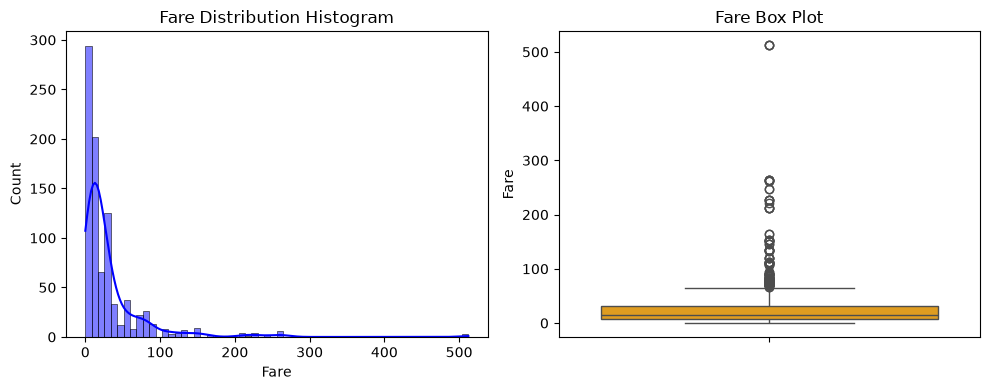

              Age        Fare
count  714.000000  891.000000
mean    29.699118   32.204208
std     14.526497   49.693429
min      0.420000    0.000000
25%     20.125000    7.910400
50%     28.000000   14.454200
75%     38.000000   31.000000
max     80.000000  512.329200
Number of passengers with 0 Fare: 15
Top 5 highest fares:
                                   Name      Fare  Pclass  Survived
258                    Ward, Miss. Anna  512.3292       1         1
679  Cardeza, Mr. Thomas Drake Martinez  512.3292       1         1
737              Lesurer, Mr. Gustave J  512.3292       1         1
27       Fortune, Mr. Charles Alexander  263.0000       1         0
88           Fortune, Miss. Mabel Helen  263.0000       1         1
Survival rate by Pclass:
    Pclass  Survived
0       1  0.629630
1       2  0.472826
2       3  0.242363


C:\Users\HP\AppData\Local\Temp\ipykernel_7044\605525609.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, palette='viridis')


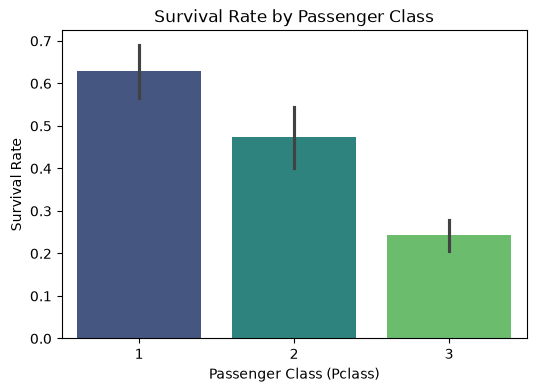

Columns in dataset: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


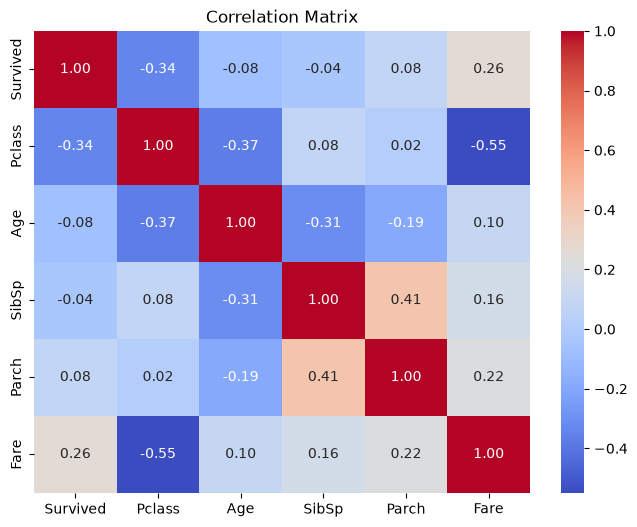

Python Version: 3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]
Pandas Version: 3.0.6
Seaborn Version: 0.13.2
Random state configured to: 42


In [ ]:
# ==========================================
# PART A: Dataset Investigation & Provenance
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('taitanic.csv')


print("Rows and Columns count:", df.shape)


print(df.head())

print(df.info())


data_dictionary = pd.escribe = pd.DataFrame({
    'Feature': df.columns,
    'Non-Null Count': df.notnull().sum(),
    'Data Type': df.dtypes,
    'Sample Value': [df[col].iloc[0] for col in df.columns]
})
print(data_dictionary)


# ==========================================
# PART B: Data Quality Audit (Missing Values & Types)
# ==========================================

missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

quality_audit = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage
})
print(quality_audit[quality_audit['Missing Count'] > 0])



# ==========================================
# PART C: Distribution Investigation
# ==========================================


plt.figure(figsize=(10, 4))

# 1. Histogram plot
plt.subplot(1, 2, 1)
sns.histplot(df['Fare'], kde=True, color='blue')
plt.title('Fare Distribution Histogram')
plt.xlabel('Fare')
plt.ylabel('Count')


plt.subplot(1, 2, 2)
sns.boxplot(y=df['Fare'], color='orange')
plt.title('Fare Box Plot')

plt.tight_layout()
plt.show()

# Summary statistics for numerical variables
print(df[['Age', 'Fare']].describe())


# ==========================================
# PART D: Find Something Strange (Anomalies/Outliers)
# ==========================================

zero_fare_count = (df['Fare'] == 0).sum()
print(f"Number of passengers with 0 Fare: {zero_fare_count}")

# 2. Check for extreme high fares (Outliers)
print("Top 5 highest fares:")
print(df.nlargest(5, 'Fare')[['Name', 'Fare', 'Pclass', 'Survived']])


# ==========================================
# PART E: Relationship Hunting (Hypothesis-First Rule)
# ==========================================


pclass_survival = df.groupby('Pclass')['Survived'].mean().reset_index()
print("Survival rate by Pclass:\n", pclass_survival)

# Visualization
plt.figure(figsize=(6, 4))
sns.barplot(x='Pclass', y='Survived', data=df, palette='viridis')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class (Pclass)')
plt.ylabel('Survival Rate')
plt.show()
# Result & Interpretation: Supported! Class 1 passengers had significantly higher survival rates.


# ==========================================
# PART F: The Hidden Leakage Challenge
# ==========================================


print("Columns in dataset:", df.columns.tolist())


# ==========================================
# PART G: Correlation vs. Causation
# ==========================================

#
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()



# ==========================================
# PART H: Reproducibility Setup Info
# ==========================================
import sys
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("Seaborn Version:", sns.__version__)

# Random state example for any modeling/splitting:
random_state = 42
print("Random state configured to:", random_state)